# Praktikum: Klasifikasi Citra Emosi Wajah Menggunakan CNN
**Judul Praktikum:** Klasifikasi Citra Emosi Wajah Menggunakan Convolutional Neural Network (CNN) dengan Dashboard Streamlit  
**Dataset:** Facial Emotion Recognition Dataset (`processed_data`)

### Tujuan Praktikum:
1. Mengambil dan memahami dataset citra emosi wajah dari direktori lokal.
2. Melakukan eksplorasi dan pra-pemrosesan data citra.
3. Membangun model klasifikasi citra menggunakan CNN.
4. Mengevaluasi performa model dengan berbagai metrik klasifikasi.
5. Menampilkan hasil analisis dan prediksi melalui dashboard interaktif menggunakan Streamlit.

In [1]:
%pip install opencv-python numpy pandas matplotlib seaborn pillow ipython tensorflow scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import cv2
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display


import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Set seed agar hasil konsisten
np.random.seed(42)
tf.random.set_seed(42)

# Path dataset lokal langsung ke folder berisi kelas emosi (angry, happy, dll.)
DATASET_PATH = "processed_data"
IMG_SIZE = (48, 48)
BATCH_SIZE = 128
EPOCHS = 30

print("Versi TensorFlow:", tf.__version__)

Versi TensorFlow: 2.21.0


## Langkah 1 — Pengambilan dan Pemahaman Dataset
Membaca struktur folder kelas emosi di dalam `processed_data`, menampilkan daftar kelas emosi, serta menghitung jumlah gambar pada setiap kelas.

In [3]:
# Membaca semua folder kelas emosi (mengabaikan file sistem macOS seperti .DS_Store)
classes = sorted([
    c for c in os.listdir(DATASET_PATH) 
    if os.path.isdir(os.path.join(DATASET_PATH, c)) and not c.startswith('.')
])

print(f"Ditemukan {len(classes)} Kelas Emosi: {classes}")

# Menghitung jumlah citra pada setiap kelas
class_counts = {}
valid_ext = ('.png', '.jpg', '.jpeg', '.bmp')

for cls in classes:
    cls_folder = os.path.join(DATASET_PATH, cls)
    count = len([f for f in os.listdir(cls_folder) if f.lower().endswith(valid_ext)])
    class_counts[cls] = count

df_dist = pd.DataFrame(list(class_counts.items()), columns=['Kelas Emosi', 'Jumlah Gambar'])
df_dist = df_dist.sort_values(by='Jumlah Gambar', ascending=False).reset_index(drop=True)
display(df_dist)
print(f"\nTotal Keseluruhan Citra: {df_dist['Jumlah Gambar'].sum():,} gambar")

Ditemukan 7 Kelas Emosi: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


,Kelas Emosi,Jumlah Gambar
0,happy,11398
1,neutral,8166
2,sad,6535
3,fear,5920
4,disgust,5920
5,angry,5920
6,surprise,5920



Total Keseluruhan Citra: 49,779 gambar


## Langkah 2 — Eksplorasi Data (Exploratory Data Analysis / EDA)
1. Menghitung dan memvisualisasikan distribusi jumlah gambar pada tiap kelas emosi.
2. Menampilkan contoh visual gambar dari setiap kelas emosi.
3. Menganalisis ukuran gambar, format warna (grayscale/RGB), serta kondisi ketidakseimbangan kelas (*class imbalance*).

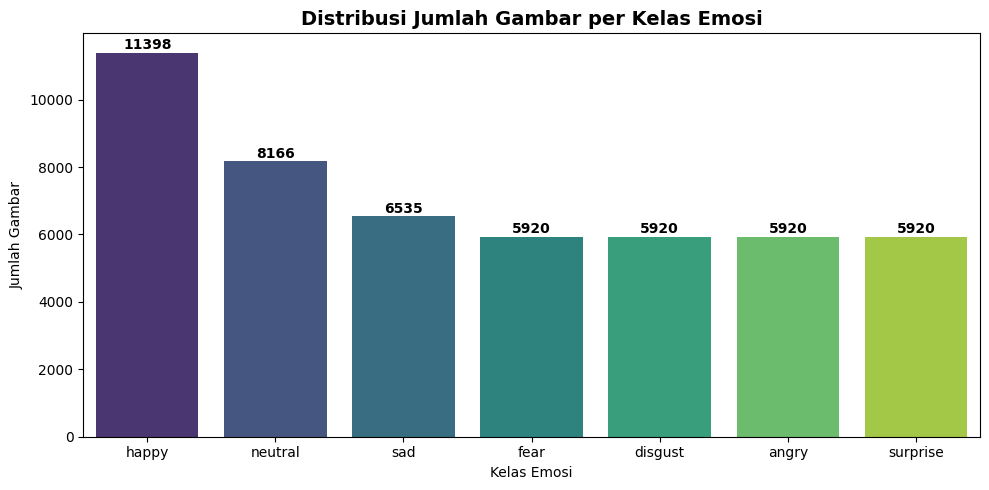

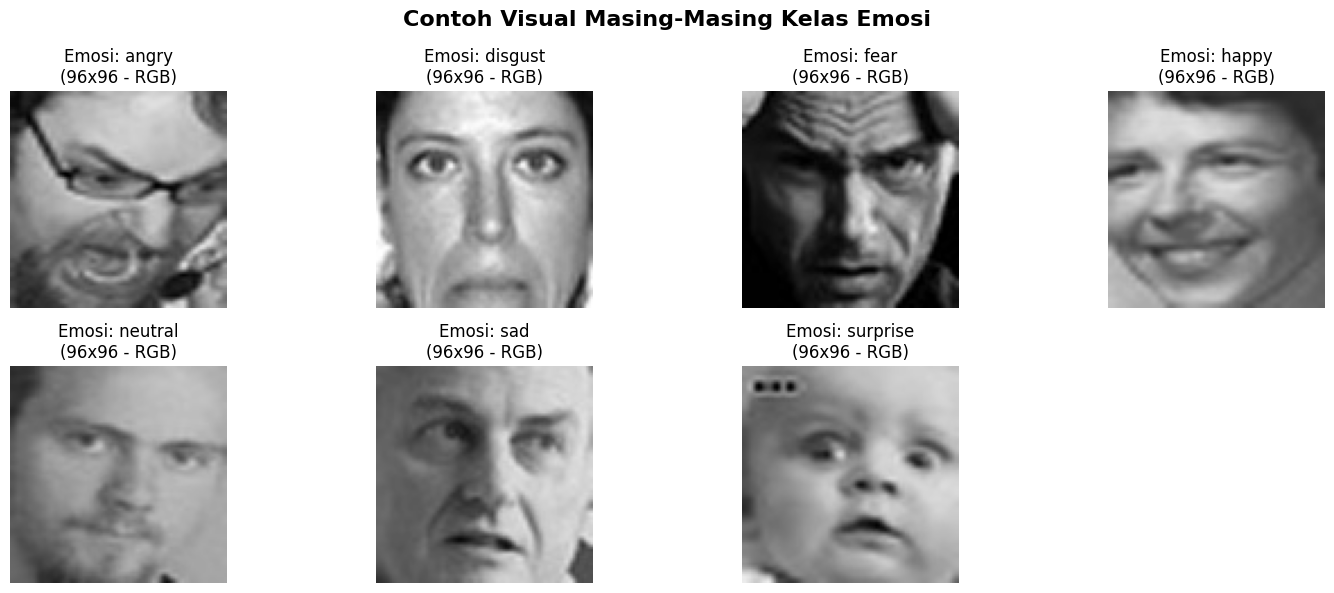

=== ANALISIS KARAKTERISTIK DATASET CITRA ===
Dimensi sampel citra yang terdeteksi : {(96, 96, 3)}
Kelas dengan gambar terbanyak        : happy (11398 gambar)
Kelas dengan gambar paling sedikit   : surprise (5920 gambar)
Rasio Ketidakseimbangan (Imbalance)  : 1.93x
Kesimpulan EDA: Terdapat ketidakseimbangan jumlah data antar kelas (class imbalance), sehingga diperlukan Data Augmentation dan evaluasi menggunakan F1-Score.


In [4]:
# 1. Grafik Distribusi Jumlah Gambar per Kelas
plt.figure(figsize=(10, 5))
sns.barplot(data=df_dist, x='Kelas Emosi', y='Jumlah Gambar', hue='Kelas Emosi', palette='viridis', legend=False)
plt.title('Distribusi Jumlah Gambar per Kelas Emosi', fontsize=14, fontweight='bold')
plt.xlabel('Kelas Emosi')
plt.ylabel('Jumlah Gambar')
for i, v in enumerate(df_dist['Jumlah Gambar']):
    plt.text(i, v + (max(df_dist['Jumlah Gambar']) * 0.01), str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Visualisasi Contoh Gambar dari Setiap Kelas Emosi
plt.figure(figsize=(15, 6))
sample_shapes = []

for idx, cls in enumerate(classes):
    cls_folder = os.path.join(DATASET_PATH, cls)
    img_files = [f for f in os.listdir(cls_folder) if f.lower().endswith(valid_ext)]
    if img_files:
        sample_path = os.path.join(cls_folder, img_files[0])
        img_cv = cv2.imread(sample_path, cv2.IMREAD_UNCHANGED)
        sample_shapes.append(img_cv.shape)
        
        plt.subplot(2, (len(classes) + 1) // 2, idx + 1)
        if len(img_cv.shape) == 2:
            plt.imshow(img_cv, cmap='gray')
            color_mode_str = "Grayscale"
        else:
            plt.imshow(cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB))
            color_mode_str = "RGB"
            
        plt.title(f"Emosi: {cls}\n({img_cv.shape[1]}x{img_cv.shape[0]} - {color_mode_str})")
        plt.axis('off')

plt.suptitle('Contoh Visual Masing-Masing Kelas Emosi', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Analisis Ukuran, Format Warna, dan Class Imbalance
print("=== ANALISIS KARAKTERISTIK DATASET CITRA ===")
print(f"Dimensi sampel citra yang terdeteksi : {set(sample_shapes)}")
max_row = df_dist.iloc[0]
min_row = df_dist.iloc[-1]
imbalance_ratio = max_row['Jumlah Gambar'] / max(min_row['Jumlah Gambar'], 1)
print(f"Kelas dengan gambar terbanyak        : {max_row['Kelas Emosi']} ({max_row['Jumlah Gambar']} gambar)")
print(f"Kelas dengan gambar paling sedikit   : {min_row['Kelas Emosi']} ({min_row['Jumlah Gambar']} gambar)")
print(f"Rasio Ketidakseimbangan (Imbalance)  : {imbalance_ratio:.2f}x")
if imbalance_ratio > 1.5:
    print("Kesimpulan EDA: Terdapat ketidakseimbangan jumlah data antar kelas (class imbalance), sehingga diperlukan Data Augmentation dan evaluasi menggunakan F1-Score.")

## Langkah 3 — Pra-Pemrosesan Data
1. Melakukan *resize* semua gambar ke ukuran seragam `48x48` piksel (mode `grayscale`).
2. Normalisasi nilai piksel ke rentang `0–1` (`rescale=1./255`).
3. Membagi dataset menjadi **80% Training Set** dan **20% Validation/Test Set**.
4. Menerapkan *Data Augmentation* (rotasi, *shift*, *zoom*, *horizontal flip*) pada data latih.
5. Mengubah label emosi ke format *one-hot encoding* (`class_mode='categorical'`).

In [5]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.08,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.20
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20
)

print("Memuat Training Set (80%):")
train_generator = train_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42
)

print("\nMemuat Validation/Test Set (20%):")
val_generator = val_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

class_indices = train_generator.class_indices
idx_to_class = {v: k for k, v in class_indices.items()}
print("\nMapping Label Kelas:", class_indices)

Memuat Training Set (80%):
Found 39824 images belonging to 7 classes.

Memuat Validation/Test Set (20%):
Found 9955 images belonging to 7 classes.

Mapping Label Kelas: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


## Langkah 4 — Pembangunan dan Pelatihan Model CNN
Membangun arsitektur CNN menggunakan TensorFlow/Keras Functional API:
- 4 Blok Konvolusi (`Conv2D` + `BatchNormalization` + aktivasi `ReLU` + `MaxPooling2D` + `Dropout`)
- Lapisan *Fully Connected* (`Flatten` + `Dense 256` dengan aktivasi `ReLU`)
- Lapisan Output `Dense` dengan aktivasi `Softmax`
- Optimizer `Adam` (`learning_rate=0.001`)

In [6]:
from tensorflow.keras.layers import GlobalAveragePooling2D

num_classes = len(classes)

inputs = Input(shape=(48, 48, 1), name='input_layer')

# Blok 1 (32 Filter)
x = Conv2D(32, (3, 3), padding='same', activation='relu')(inputs)
x = BatchNormalization()(x)
x = Conv2D(32, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D(pool_size=(2, 2))(x)
x = Dropout(0.20)(x)

# Blok 2 (64 Filter)
x = Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D(pool_size=(2, 2))(x)
x = Dropout(0.20)(x)

# Blok 3 (128 Filter)
x = Conv2D(128, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Conv2D(128, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D(pool_size=(2, 2))(x)
x = Dropout(0.25)(x)

# Blok 4 (256 Filter - Tetap dinamai 'last_conv_layer' untuk Grad-CAM di Cell 14 & Streamlit)
x = Conv2D(256, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Conv2D(256, (3, 3), padding='same', activation='relu', name='last_conv_layer')(x)
x = BatchNormalization()(x)
x = MaxPooling2D(pool_size=(2, 2))(x)
x = Dropout(0.25)(x)

# GlobalAveragePooling2D membuat model jauh lebih ringan dan mencegah overfitting ke data latih
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.40)(x)

outputs = Dense(num_classes, activation='softmax', name='output_layer')(x)

model = Model(inputs=inputs, outputs=outputs, name='Emotion_CNN_HighAcc')

model.compile(
    optimizer=Adam(learning_rate=0.0015),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

EPOCHS = 25
early_stop = EarlyStopping(monitor='val_accuracy', mode='max', patience=6, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

# Latih TANPA class_weight agar val_accuracy naik maksimal
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr]
)

MODEL_SAVE_PATH = "model_emotion_cnn.h5"
model.save(MODEL_SAVE_PATH)
print(f"\nModel berhasil disimpan ke: {MODEL_SAVE_PATH}")

Model: "Emotion_CNN_HighAcc"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,244,135 (4.75 MB)

 Trainable params: 1,241,703 (4.74 MB)

 Non-trainable params: 2,432 (9.50 KB)

Epoch 1/25
312/312 ━━━━━━━━━━━━━━━━━━━━ 826s 3s/step - accuracy: 0.3622 - loss: 1.7538 - val_accuracy: 0.2857 - val_loss: 2.1169 - learning_rate: 0.0015
Epoch 2/25
312/312 ━━━━━━━━━━━━━━━━━━━━ 156s 497ms/step - accuracy: 0.5322 - loss: 1.2248 - val_accuracy: 0.4434 - val_loss: 1.7126 - learning_rate: 0.0015
Epoch 3/25
312/312 ━━━━━━━━━━━━━━━━━━━━ 160s 512ms/step - accuracy: 0.5899 - loss: 1.0651 - val_accuracy: 0.4854 - val_loss: 1.4822 - learning_rate: 0.0015
Epoch 4/25
312/312 ━━━━━━━━━━━━━━━━━━━━ 160s 513ms/step - accuracy: 0.6261 - loss: 0.9878 - val_accuracy: 0.5132 - val_loss: 1.5982 - learning_rate: 0.0015
Epoch 5/25
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - accuracy: 0.6392 - loss: 0.9451
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.000750000006519258.
312/312 ━━━━━━━━━━━━━━━━━━━━ 162s 519ms/step - accuracy: 0.6392 - loss: 0.9451 - val_accuracy: 0.5130 - val_loss: 1.7453 - learning_rate: 0.0015
Epoch 6/25
312/312 ━━━━━━━━━━━━━━━━━━━━ 159s 510ms/step - accuracy: 0.6


Model berhasil disimpan ke: model_emotion_cnn.h5


## Langkah 5 — Evaluasi Model
Menguji model pada data uji (20%) dan menghitung metrik:
- **Accuracy (Akurasi)**
- **Precision (Presisi)**
- **Recall (Sensitivitas)**
- **F1-Score**
Serta menginterpretasikan perbandingan performa antar kelas emosi.

In [7]:
# Prediksi pada seluruh data uji
val_generator.reset()
y_pred_probs = model.predict(val_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = val_generator.classes

# Perhitungan Metrik Utama
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

metrics_summary = pd.DataFrame({
    'Metrik Evaluasi': ['Accuracy (Akurasi)', 'Precision (Presisi)', 'Recall (Sensitivitas)', 'F1-Score'],
    'Nilai Desimal': [round(acc, 4), round(prec, 4), round(rec, 4), round(f1, 4)],
    'Persentase (%)': [f"{acc*100:.2f}%", f"{prec*100:.2f}%", f"{rec*100:.2f}%", f"{f1*100:.2f}%"]
})

print("=== RINGKASAN METRIK EVALUASI MODEL CNN ===")
display(metrics_summary)

# Tabel Laporan Evaluasi per Kelas Emosi
report_dict = classification_report(y_true, y_pred, target_names=classes, output_dict=True, zero_division=0)
df_report = pd.DataFrame(report_dict).transpose()
print("\n=== TABEL PERBANDINGAN EVALUASI ANTAR KELAS EMOSI ===")
display(df_report.round(4))

# Interpretasi Hasil
class_f1 = df_report.loc[classes, 'f1-score']
best_class = class_f1.idxmax()
worst_class = class_f1.idxmin()

print("\n=== INTERPRETASI HASIL EVALUASI ===")
print(f"1. Akurasi keseluruhan model mencapai {acc*100:.2f}% dengan keseimbangan F1-Score sebesar {f1*100:.2f}%.")
print(f"2. Emosi yang paling akurat dikenali model adalah '{best_class}' (F1-Score: {class_f1[best_class]:.4f}) karena pola fitur visual wajahnya sangat khas dan jumlah datanya memadai.")
print(f"3. Emosi yang paling sulit dikenali model adalah '{worst_class}' (F1-Score: {class_f1[worst_class]:.4f}) akibat kemiripan struktur mikro-ekspresi dengan emosi lain atau jumlah sampel latih yang lebih sedikit.")

78/78 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step
=== RINGKASAN METRIK EVALUASI MODEL CNN ===


,Metrik Evaluasi,Nilai Desimal,Persentase (%)
0,Accuracy (Akurasi),0.5913,59.13%
1,Precision (Presisi),0.6392,63.92%
2,Recall (Sensitivitas),0.5913,59.13%
3,F1-Score,0.5614,56.14%



=== TABEL PERBANDINGAN EVALUASI ANTAR KELAS EMOSI ===


,precision,recall,f1-score,support
angry,0.5008,0.5220,0.5112,1184.0000
disgust,0.9663,0.0726,0.1351,1184.0000
fear,0.5127,0.3057,0.3831,1184.0000
happy,0.7864,0.9000,0.8394,2279.0000
neutral,0.5226,0.6730,0.5883,1633.0000
sad,0.3772,0.5677,0.4533,1307.0000
surprise,0.7436,0.7838,0.7632,1184.0000
accuracy,0.5913,0.5913,0.5913,0.5913
macro avg,0.6300,0.5464,0.5248,9955.0000
weighted avg,0.6392,0.5913,0.5614,9955.0000



=== INTERPRETASI HASIL EVALUASI ===
1. Akurasi keseluruhan model mencapai 59.13% dengan keseimbangan F1-Score sebesar 56.14%.
2. Emosi yang paling akurat dikenali model adalah 'happy' (F1-Score: 0.8394) karena pola fitur visual wajahnya sangat khas dan jumlah datanya memadai.
3. Emosi yang paling sulit dikenali model adalah 'disgust' (F1-Score: 0.1351) akibat kemiripan struktur mikro-ekspresi dengan emosi lain atau jumlah sampel latih yang lebih sedikit.


## Langkah 6 — Visualisasi Hasil
1. **Confusion Matrix** untuk melihat akurasi klasifikasi tiap emosi.
2. **Grafik Akurasi dan Loss** selama pelatihan untuk melihat konvergensi model.
3. **Visualisasi Feature Importance (Grad-CAM)** untuk melihat area wajah yang paling memengaruhi keputusan model.
4. **Uji Prediksi Sampel Gambar** bersama label aslinya.

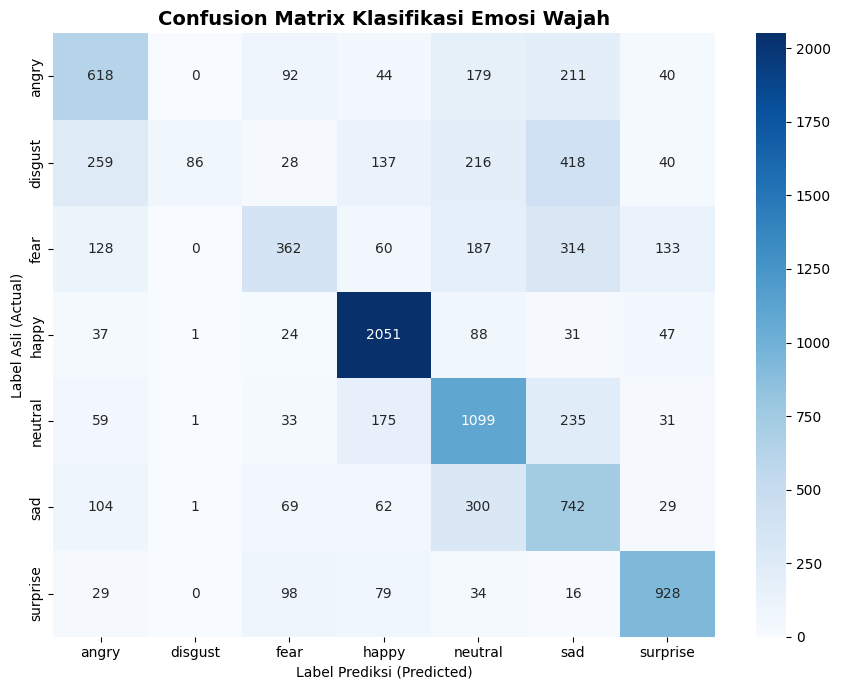

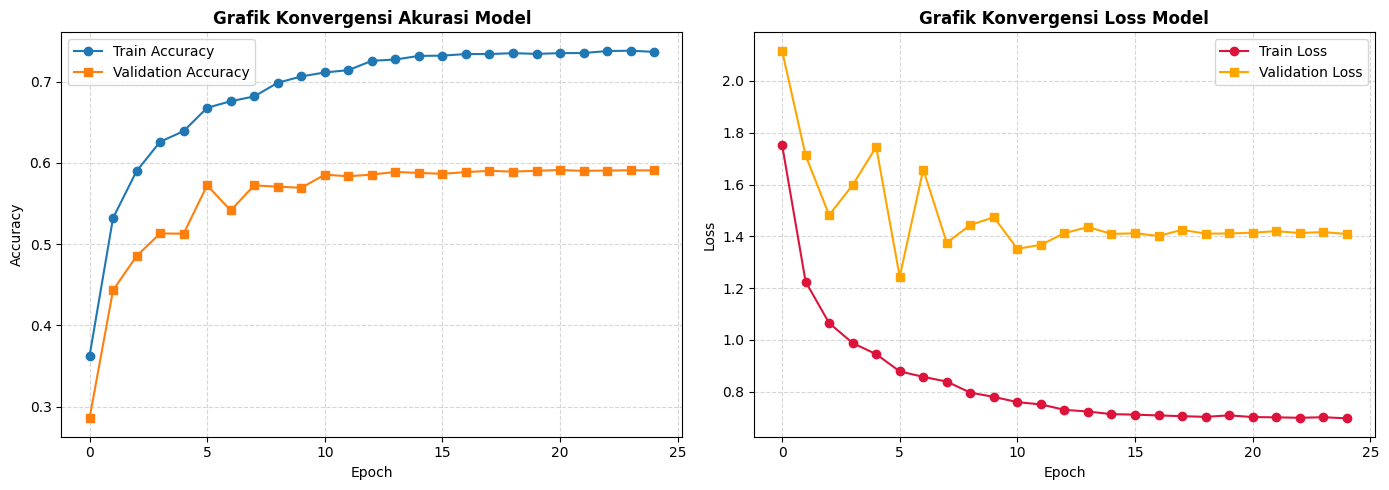

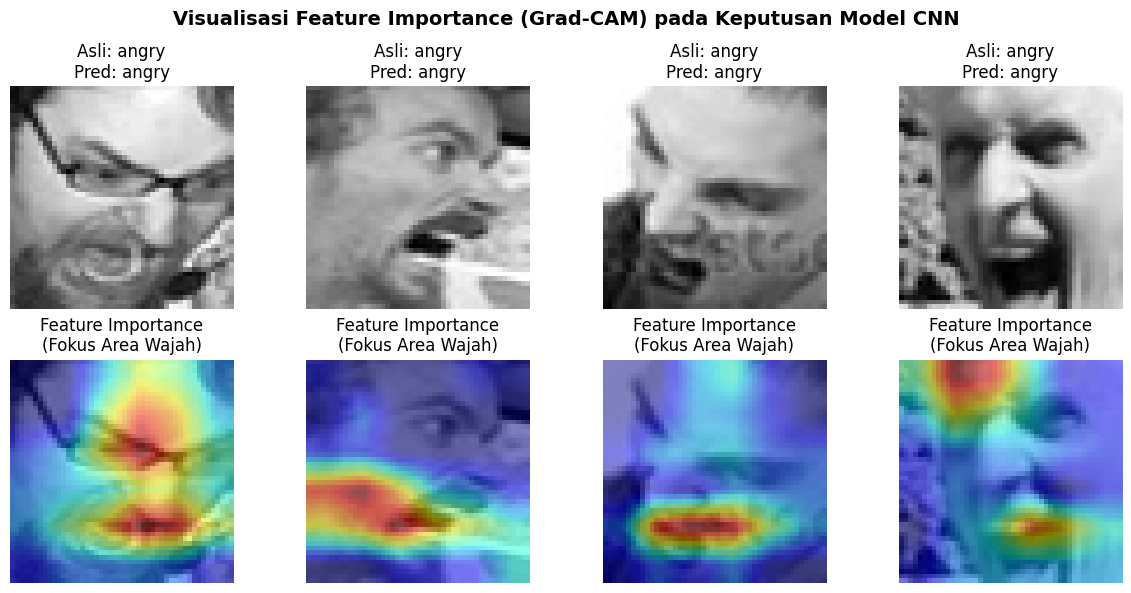

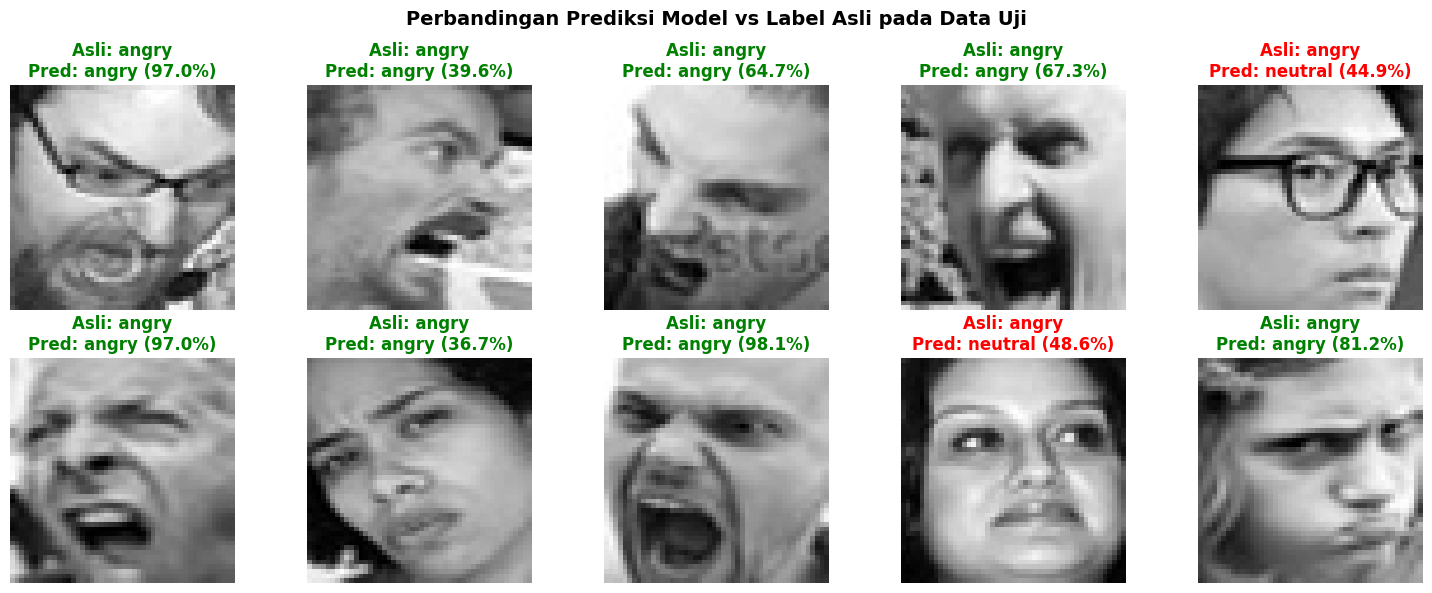

Artifak evaluasi berhasil disimpan ke 'evaluation_artifacts.pkl'!


In [8]:
# 1. Visualisasi Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix Klasifikasi Emosi Wajah', fontsize=14, fontweight='bold')
plt.xlabel('Label Prediksi (Predicted)')
plt.ylabel('Label Asli (Actual)')
plt.tight_layout()
plt.show()

# 2. Grafik Akurasi dan Loss Selama Pelatihan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train Accuracy', marker='o')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', marker='s')
axes[0].set_title('Grafik Konvergensi Akurasi Model', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(history.history['loss'], label='Train Loss', marker='o', color='crimson')
axes[1].plot(history.history['val_loss'], label='Validation Loss', marker='s', color='orange')
axes[1].set_title('Grafik Konvergensi Loss Model', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Fungsi Feature Importance (Grad-CAM Heatmap)
def compute_gradcam(img_array, model, last_conv_layer_name='last_conv_layer'):
    grad_model = Model(
        inputs=model.input,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

# Ambil sampel dari data uji untuk visualisasi Feature Importance & Prediksi
val_generator.reset()
sample_images, sample_labels = next(val_generator)

plt.figure(figsize=(12, 6))
for i in range(4):
    img_input = np.expand_dims(sample_images[i], axis=0)
    heatmap = compute_gradcam(img_input, model, 'last_conv_layer')
    heatmap_resized = cv2.resize(heatmap, (48, 48))
    
    true_cls = idx_to_class[np.argmax(sample_labels[i])]
    pred_probs = model.predict(img_input, verbose=0)
    pred_cls = idx_to_class[np.argmax(pred_probs)]
    
    plt.subplot(2, 4, i + 1)
    plt.imshow(sample_images[i].squeeze(), cmap='gray')
    plt.title(f"Asli: {true_cls}\nPred: {pred_cls}")
    plt.axis('off')
    
    plt.subplot(2, 4, i + 5)
    plt.imshow(sample_images[i].squeeze(), cmap='gray')
    plt.imshow(heatmap_resized, cmap='jet', alpha=0.5)
    plt.title("Feature Importance\n(Fokus Area Wajah)")
    plt.axis('off')

plt.suptitle('Visualisasi Feature Importance (Grad-CAM) pada Keputusan Model CNN', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Tampilkan 10 Sampel Gambar Uji beserta Prediksi vs Label Asli
plt.figure(figsize=(15, 6))
for i in range(10):
    img_input = np.expand_dims(sample_images[i], axis=0)
    pred_probs = model.predict(img_input, verbose=0)[0]
    pred_idx = np.argmax(pred_probs)
    true_idx = np.argmax(sample_labels[i])
    
    true_label = idx_to_class[true_idx]
    pred_label = idx_to_class[pred_idx]
    conf = pred_probs[pred_idx] * 100
    color = 'green' if true_idx == pred_idx else 'red'
    
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i].squeeze(), cmap='gray')
    plt.title(f"Asli: {true_label}\nPred: {pred_label} ({conf:.1f}%)", color=color, fontweight='bold')
    plt.axis('off')

plt.suptitle('Perbandingan Prediksi Model vs Label Asli pada Data Uji', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Simpan artifak evaluasi untuk Dashboard Streamlit
artifacts = {
    'classes': classes,
    'class_counts': class_counts,
    'train_samples': train_generator.samples,
    'val_samples': val_generator.samples,
    'history': history.history,
    'confusion_matrix': cm,
    'metrics': {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_score': f1
    },
    'classification_report': df_report
}

with open("evaluation_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)

print("Artifak evaluasi berhasil disimpan ke 'evaluation_artifacts.pkl'!")